# Decision Tree Classifier on Iris Dataset

In this lab, we implement the **Decision Tree Classifier** on the built-in Iris dataset.
Decision trees partition the feature space using recursive binary splits based on purity criteria.

#### Splitting Criteria from Syllabus:
1. **Gini Impurity**:
   $$Gini(S) = 1 - \sum_{i=1}^C p_i^2$$
2. **Entropy & Information Gain**:
   $$H(S) = -\sum_{i=1}^C p_i \log_2(p_i)$$
   $$IG(S, A) = H(S) - \sum_{v \in \text{Values}(A)} \frac{|S_v|}{|S|} H(S_v)$$

### 1. Importing the necessary modules

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

### 2. Loading the built-in Iris dataset directly from scikit-learn

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
df['species'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### 3. Exploring dataset information and checking for missing values

In [3]:
print("Dataset shape:", df.shape)
print("\nMissing values per column:\n", df.isnull().sum())
print("\nClass distribution:\n", df['species'].value_counts())
df.describe()

Dataset shape: (150, 6)

Missing values per column:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Class distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


### 4. Slicing feature matrix X and target vector y

In [4]:
X = df[iris.feature_names]
y = df['target']

print("Features (X):")
print(X.head())
print("\nTarget (y):")
print(y.head())

Features (X):
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target (y):
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


### 5. Splitting dataset into Training and Test sets (Stratified)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

Training samples: 120
Testing samples: 30
X_train shape: (120, 4), X_test shape: (30, 4)


### 6. Training the Decision Tree Classifier (Gini Impurity criterion)

In [6]:
dt_model = DecisionTreeClassifier(criterion="gini", random_state=42)
dt_model.fit(X_train, y_train)

print("Decision Tree Model successfully trained!")
print("Tree Depth:", dt_model.get_depth())
print("Number of Leaves:", dt_model.get_n_leaves())

Decision Tree Model successfully trained!
Tree Depth: 5
Number of Leaves: 8


### 7. Predicting the Test set results

In [7]:
y_pred_dt = dt_model.predict(X_test)

comparison_df = pd.DataFrame({
    "Actual Class": [iris.target_names[i] for i in y_test],
    "Predicted Class": [iris.target_names[i] for i in y_pred_dt]
})
comparison_df.head(10)

,Actual Class,Predicted Class
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


### 8. Evaluating Model Performance (Accuracy, Confusion Matrix, Classification Report)

In [8]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
cm_dt = confusion_matrix(y_test, y_pred_dt)

print(f"Decision Tree Accuracy: {accuracy_dt * 100:.2f}%")
print()
print("Confusion Matrix:")
print(cm_dt)
print()
print("Classification Report:")
print(classification_report(y_test, y_pred_dt, target_names=iris.target_names))

Decision Tree Accuracy: 93.33%

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



### 9. Visualizing the Decision Tree diagram

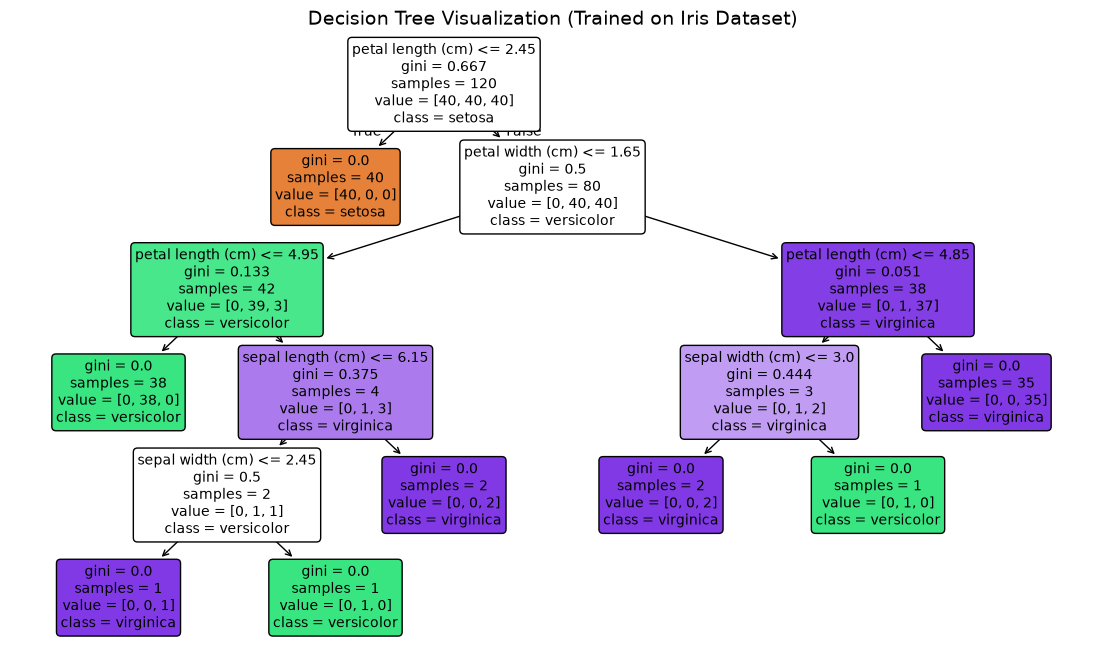

In [9]:
plt.figure(figsize=(14, 8))
plot_tree(
    dt_model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization (Trained on Iris Dataset)", fontsize=14)
plt.show()

### 10. Visualizing the Confusion Matrix

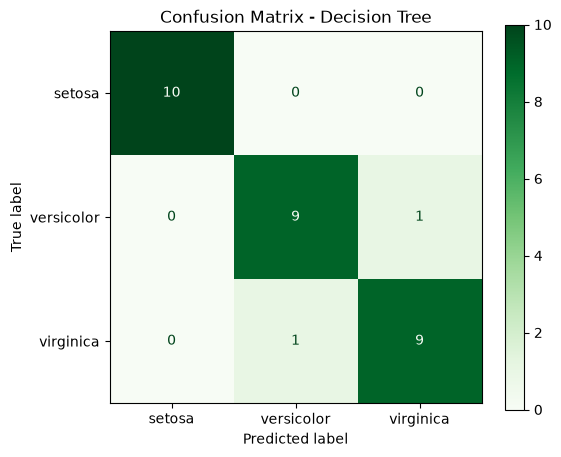

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=iris.target_names)
disp.plot(cmap=plt.cm.Greens, ax=ax)
plt.title("Confusion Matrix - Decision Tree")
plt.grid(False)
plt.show()

### 11. Syllabus Comparison: Gini Impurity vs Information Gain (Entropy)

In [11]:
dt_entropy = DecisionTreeClassifier(criterion="entropy", random_state=42)
dt_entropy.fit(X_train, y_train)
y_pred_entropy = dt_entropy.predict(X_test)

print(f"Gini Criterion Accuracy:    {accuracy_dt * 100:.2f}% (Depth: {dt_model.get_depth()})")
print(f"Entropy Criterion Accuracy: {accuracy_score(y_test, y_pred_entropy) * 100:.2f}% (Depth: {dt_entropy.get_depth()})")

Gini Criterion Accuracy:    93.33% (Depth: 5)
Entropy Criterion Accuracy: 93.33% (Depth: 5)
